**Neural networks, perceptron, backpropagation, optimization, autoencoders, and VAE**
-

**Libraries**
-

In [1]:
from pathlib import Path
import sys

working_directory = Path.cwd().resolve()
candidates = [working_directory, *working_directory.parents]
# Discover a project below the current folder without assuming its name.
for pattern in ("*/src/config.py", "*/*/src/config.py"):
    candidates.extend(path.parent.parent for path in working_directory.glob(pattern))
project_root = next(
    (path for path in candidates
     if (path / "src" / "config.py").is_file()
     and (path / "notebooks" / "main.ipynb").is_file()),
    None,
)
if project_root is None:
    raise RuntimeError("Project not found. Open from the project, notebooks, or containing workspace folder.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.models.neural_networks import (
    configure, NeuralData, Autoencoder, AETrainer, AESearch, AEAnalysis,
    VAESearch, VAEAnalysis,
)
from src.evaluation.ae_stability import AESeedStability
from src.evaluation.neural_networks import VAESeedTrainer, VAESeedStability, VAEAnomalyAnalysis
from src.models.neural_network_plots import (
    plot_ae_search, plot_ae_stability, plot_ae_correlations,
    plot_vae_history, plot_vae_score_distribution, plot_vae_stability,
)

configure(seed=42)


Device: cpu


## **1. Question of Interest**

- How can an autoencoder learn latent representations from the numerical features of orders, and how can a variational autoencoder (VAE) use reconstruction errors to identify potentially anomalous orders?

## **2. Database Loading and Split**

### **2.1 Database Loading**

In [2]:
data = NeuralData()
df = data.frame


In [3]:
df.head()


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Name,Customer City,Customer Country,...,Order Item Quantity,Sales,Order Region,Order State,Order Status,Product Card Id,Product Name,Product Price,Shipping Mode,Order Month
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,Sporting Goods,Caguas,Puerto Rico,...,1,327.75,Southeast Asia,Java Occidental,COMPLETE,1360,Smart watch,327.75,Standard Class,1
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,Sporting Goods,Caguas,Puerto Rico,...,1,327.75,South Asia,Rajastán,PENDING,1360,Smart watch,327.75,Standard Class,1
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,Sporting Goods,San Jose,EE. UU.,...,1,327.75,South Asia,Rajastán,CLOSED,1360,Smart watch,327.75,Standard Class,1
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,Sporting Goods,Los Angeles,EE. UU.,...,1,327.75,Oceania,Queensland,COMPLETE,1360,Smart watch,327.75,Standard Class,1
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,Sporting Goods,Caguas,Puerto Rico,...,1,327.75,Oceania,Queensland,PENDING_PAYMENT,1360,Smart watch,327.75,Standard Class,1


In [4]:
X = data.select_features()


### **2.2 Split and Standarization**

In [5]:
data = data.prepare()


## **3. Perceptron**

**1. What is a Perceptron?**

A perceptron is the basic computational unit of an artificial neural network. It receives several input values, multiplies them by weights, adds a bias, and applies an activation function to produce an output.
How does it work?

Mathematically, a neuron computes:

$$
\boxed{\hat y=f\left(\sum_{j=1}^{p}w_jx_j+b\right)}
$$

Where:
- $x_j$: Input feature.
- $w_j$: Weight assigned to each feature.
- $b$: Bias.
- $f$: Activation function.
- $\hat y$: Predicted output.


**2. Numerical example**

Suppose a neuron receives two inputs:
$$
x_1=2,\quad x_2=3
$$

With weights and bias:

$$
w_1=0.5,\quad w_2=-0.2,\quad b=0.1
$$

First, calculate the weighted sum:

$$
z=(0.5)(2)+(-0.2)(3)+0.1=0.5
$$

Then apply an activation function, such as ReLU:

$$
f(z)=\max(0,z)
$$

Therefore:
$$
\boxed{\hat y=0.5}
$$

![Perceptron Architecture](../results/07_autoencoder_vae/figures/perceptron.png)

## **4. Backpropagation**

**Backpropagation** is an algorithm used to calculate how each weight and bias in a neural network contributes to the prediction error.

While the **forward pass** produces a prediction, backpropagation calculates the gradients needed to improve that prediction.

It uses the **chain rule of calculus** to propagate information about the error backward through the network.

**1. How does it work?**

A neural network learns through three main stages:

1. **Forward pass:** Calculate the prediction.
2. **Loss calculation:** Measure the prediction error.
3. **Backward pass:** Calculate the gradients.

**Step 1 — Forward propagation**

The inputs pass through the neurons, producing a prediction:

$$
\hat y=f(wx+b)
$$

**Step 2 — Calculate the loss**

We measure the difference between the prediction and the actual value. For example, using squared error:

$$
L=(y-\hat y)^2
$$

**Step 3 — Backpropagation**

We calculate how the loss changes with respect to each parameter:

$$
\boxed{\frac{\partial L}{\partial w},\quad \frac{\partial L}{\partial b}}
$$

These derivatives are called **gradients**.

A positive gradient indicates that increasing the parameter would locally increase the loss, while a negative gradient indicates the opposite.

**2. Why is the chain rule important?**

Consider a single neuron:

$$
z=wx+b,\qquad \hat y=f(z)
$$

The loss depends on the weight indirectly:

$$
w\rightarrow z\rightarrow \hat y\rightarrow L
$$

Therefore, we use the chain rule:

$$
\boxed{
\frac{\partial L}{\partial w}
=
\frac{\partial L}{\partial \hat y}
\cdot
\frac{\partial \hat y}{\partial z}
\cdot
\frac{\partial z}{\partial w}
}
$$

This allows us to calculate how changing a weight affects the final error, even when the network contains multiple layers.

**3. Numerical example**

Suppose we have a neuron with a linear activation function:

$$
x=2,\quad w=0.5,\quad b=0,\quad y=3
$$

The prediction is:

$$
\hat y=wx+b=(0.5)(2)=1
$$

The squared error is:

$$
L=(3-1)^2=4
$$

Now calculate the gradient:

$$
\frac{\partial L}{\partial w}
=2(\hat y-y)x
$$

$$
=2(1-3)(2)=\boxed{-8}
$$

The negative gradient tells us that increasing the weight will reduce the loss locally.

**4. How are the weights updated?**

Backpropagation only **calculates the gradients**. An optimization algorithm, such as gradient descent or Adam, uses those gradients to update the parameters.

For gradient descent:

$$
\boxed{w_{\text{new}}=w_{\text{old}}-\eta\frac{\partial L}{\partial w}}
$$

Where $\eta$ is the learning rate.

For example, with $\eta=0.1$:

$$
w_{\text{new}}=0.5-0.1(-8)=1.3
$$

The new prediction becomes:

$$
\hat y=(1.3)(2)=2.6
$$

And the new loss is:

$$
L=(3-2.6)^2=\boxed{0.16}
$$

| Metric | Before update | After update |
|---|---|---|
| Weight | 0.5 | 1.3 |
| Prediction | 1.0 | 2.6 |
| Squared error | 4.00 | 0.16 |

The error decreased after one weight update.

**The key distinction:** Backpropagation computes the gradients; optimization uses those gradients to change the weights and minimize the loss.

![Backpropagation Pipeline](../results/07_autoencoder_vae/figures/backpropagation.png)

## **5. Optimization**

**Optimization** is the process of adjusting the weights and biases of a neural network to minimize a loss function.

While **backpropagation calculates the gradients**, optimization uses those gradients to update the model parameters and reduce prediction errors.

The objective is to find the parameters that minimize the loss:

$$
\boxed{\theta^*=\arg\min_\theta L(\theta)}
$$

Where:

- $\theta$: Model parameters (weights and biases).
- $L(\theta)$: Loss function.
- $\theta^*$: Parameters that minimize the loss.

**1. Gradient Descent**

**Gradient Descent** is a fundamental optimization algorithm that updates parameters in the opposite direction of the gradient, since the gradient indicates the direction of greatest local increase in the loss.

The update rule is:

$$
\boxed{\theta_{t+1}=\theta_t-\eta g_t}
$$

Where:

- $\theta_t$: Current parameters.
- $\eta$: Learning rate.
- $g_t=\nabla_\theta L(\theta_t)$: Current gradient.
- $\theta_{t+1}$: Updated parameters.

The learning rate controls the size of each update. A small learning rate may result in slow convergence, while an excessively large learning rate may cause oscillations or divergence.

**2. Momentum**

**Momentum** improves Gradient Descent by incorporating information from previous gradients rather than relying exclusively on the current gradient.

It maintains an exponential moving average of gradients:

$$
\boxed{m_t=\beta m_{t-1}+(1-\beta)g_t}
$$

The parameters are then updated using:

$$
\boxed{\theta_{t+1}=\theta_t-\eta m_t}
$$

Where:

- $m_t$: Moving average of gradients.
- $\beta$: Momentum coefficient, commonly 0.9.
- $g_t$: Current gradient.
- $\eta$: Learning rate.

Momentum helps accelerate optimization when gradients consistently point in the same direction and reduces oscillations when gradients alternate directions.

**Numerical Example — Momentum**

Suppose:

$$
\theta_0=2,\quad \eta=0.1,\quad \beta=0.9,\quad m_0=0
$$

**First iteration:** With gradient $g_1=4$:

$$
m_1=0.9(0)+0.1(4)=0.4
$$

$$
\theta_1=2-0.1(0.4)=\boxed{1.96}
$$

**Second iteration:** With gradient $g_2=3$:

$$
m_2=0.9(0.4)+0.1(3)=0.66
$$

$$
\theta_2=1.96-0.1(0.66)=\boxed{1.894}
$$

The second update incorporates information from both the previous and current gradients.

**3. RMSprop**

**RMSprop (Root Mean Square Propagation)** adapts the learning rate of each parameter based on the magnitude of its recent gradients.

It maintains an exponential moving average of squared gradients:

$$
\boxed{v_t=\beta v_{t-1}+(1-\beta)g_t^2}
$$

The parameter update is:

$$
\boxed{\theta_{t+1}=\theta_t-\frac{\eta}{\sqrt{v_t}+\epsilon}g_t}
$$

Where:

- $v_t$: Moving average of squared gradients.
- $\beta$: Decay coefficient, commonly 0.9.
- $\epsilon$: Small constant for numerical stability.

RMSprop reduces the effective learning rate for parameters with consistently large gradients and increases it relative to parameters with smaller gradients.

**Numerical Example — RMSprop**

Suppose:

$$
\theta_0=2,\quad \eta=0.1,\quad \beta=0.9,\quad v_0=0
$$

Assume $\epsilon$ is sufficiently small to neglect in the calculations.

**First iteration:** With gradient $g_1=4$:

$$
v_1=0.9(0)+0.1(4^2)=1.6
$$

$$
\theta_1=2-\frac{0.1(4)}{\sqrt{1.6}}
$$

$$
\boxed{\theta_1\approx1.6838}
$$

**Second iteration:** With gradient $g_2=3$:

$$
v_2=0.9(1.6)+0.1(3^2)=2.34
$$

$$
\theta_2=1.6838-\frac{0.1(3)}{\sqrt{2.34}}
$$

$$
\boxed{\theta_2\approx1.4877}
$$

Unlike Momentum, RMSprop uses squared gradients to adjust the magnitude of parameter updates.

**4. Adam**

**Adam (Adaptive Moment Estimation)** combines the main ideas of Momentum and RMSprop by maintaining two moving averages.

**First moment — Momentum-like behavior:**

$$
\boxed{m_t=\beta_1m_{t-1}+(1-\beta_1)g_t}
$$

**Second moment — RMSprop-like behavior:**

$$
\boxed{v_t=\beta_2v_{t-1}+(1-\beta_2)g_t^2}
$$

Where:

- $m_t$: Moving average of gradients.
- $v_t$: Moving average of squared gradients.
- $\beta_1$: First-moment decay coefficient, commonly 0.9.
- $\beta_2$: Second-moment decay coefficient, commonly 0.999.

Because these moving averages are initialized at zero, Adam applies bias correction:

$$
\hat m_t=\frac{m_t}{1-\beta_1^t},
\qquad
\hat v_t=\frac{v_t}{1-\beta_2^t}
$$

The final update rule is:

$$
\boxed{
\theta_{t+1}
=
\theta_t-\eta\frac{\hat m_t}{\sqrt{\hat v_t}+\epsilon}
}
$$

Adam combines the directional information from Momentum with the adaptive update sizes of RMSprop.

**Numerical Example — Adam**

Suppose:

$$
\theta_0=2,\quad \eta=0.1,\quad \beta_1=0.9,\quad \beta_2=0.999
$$

With $m_0=v_0=0$ and negligible $\epsilon$.

**First iteration:** With gradient $g_1=4$:

Calculate the first and second moments:

$$
m_1=0.9(0)+0.1(4)=0.4
$$

$$
v_1=0.999(0)+0.001(4^2)=0.016
$$

Apply bias correction:

$$
\hat m_1=\frac{0.4}{1-0.9}=4
$$

$$
\hat v_1=\frac{0.016}{1-0.999}=16
$$

Update the parameter:

$$
\theta_1=2-0.1\frac{4}{\sqrt{16}}
$$

$$
\boxed{\theta_1=1.9}
$$

**Second iteration:** With gradient $g_2=3$:

$$
m_2=0.9(0.4)+0.1(3)=0.66
$$

$$
v_2=0.999(0.016)+0.001(3^2)=0.024984
$$

Apply bias correction:

$$
\hat m_2=\frac{0.66}{1-0.9^2}\approx3.4737
$$

$$
\hat v_2=\frac{0.024984}{1-0.999^2}\approx12.4982
$$

Update:

$$
\theta_2=1.9-0.1\frac{3.4737}{\sqrt{12.4982}}
$$

$$
\boxed{\theta_2\approx1.8017}
$$

Adam incorporates the history of gradients through the first moment and adjusts parameter updates using the second moment.

**5. Comparison of Optimization Algorithms**

| Characteristic | Gradient Descent | Momentum | RMSprop | Adam |
|---|---|---|---|---|
| **Uses current gradient** | Yes | Yes | Yes | Yes |
| **Uses previous gradients** | No | Yes | Through squared gradients | Yes |
| **Adaptive learning rate** | No | No | Yes | Yes |
| **Reduces oscillations** | Limited | Yes | Often | Often |
| **Main advantage** | Simple implementation | Accelerates convergence | Adapts parameter updates | Combines momentum and adaptive scaling |
| **Main limitation** | Can converge slowly | Requires tuning momentum and learning rate | Sensitive to hyperparameters | Higher computational and memory requirements |

**Numerical Comparison**

Using the same initial parameter $\theta_0=2$, learning rate $\eta=0.1$, and illustrative gradients $g_1=4$ and $g_2=3$:

| Optimizer | Initial parameter | Iteration 1 | Iteration 2 |
|---|---:|---:|---:|
| Momentum | 2.0000 | 1.9600 | 1.8940 |
| RMSprop | 2.0000 | 1.6838 | 1.4877 |
| Adam | 2.0000 | 1.9000 | 1.8017 |

These results demonstrate how the algorithms update parameters differently. Larger updates do not necessarily imply faster convergence or better optimization.

**6. Epochs, Batches, and Iterations**

Optimization is performed repeatedly during neural network training.

- **Epoch:** One complete pass through the training dataset.
- **Batch:** A subset of training observations processed together.
- **Iteration:** One parameter update using a batch.

For example, with 1,000 training observations and a batch size of 100:

$$
\text{Iterations per epoch}=\frac{1000}{100}=10
$$

Training for 50 epochs produces:

$$
\boxed{10\times50=500\text{ parameter updates}}
$$

**In summary:** Gradient Descent updates parameters using the current gradient, Momentum incorporates previous gradients, RMSprop adapts learning rates using squared gradients, and Adam combines momentum-based and adaptive optimization techniques.


![Backpropagation Pipeline](../results/07_autoencoder_vae/figures/optimization.png)

## **6. Auto-Encoder (AE)**

### **6.1 Notation**

An **Autoencoder (AE)** is an unsupervised representation-learning neural network designed to learn a compressed representation of input data and reconstruct the original input from that representation.

Unlike traditional supervised learning, an Autoencoder does not require class labels. Instead, it uses the input itself as the target.

Its objective is to learn a function:

$$
\boxed{\hat{x}=f_\theta(x)}
$$

Where:

- $x$: Original input.
- $\hat{x}$: Reconstructed input.
- $f_\theta$: Autoencoder parameterized by weights and biases.

The goal is to produce a reconstruction $\hat{x}$ that is as similar as possible to $x$.

---

**1. Autoencoder Architecture**

An Autoencoder consists of three main components:

**1.1 Encoder**

The **Encoder** transforms the original input into a lower-dimensional representation.

$$
\boxed{z=f_\phi(x)}
$$

Where:

- $x\in\mathbb{R}^{p}$: Original input containing $p$ features.
- $z\in\mathbb{R}^{k}$: Latent representation.
- $f_\phi$: Encoder function.
- $k$: Latent dimensionality, often $k<p$.

For example, if our dataset contains 10 numerical features, the Encoder could transform them into 3 latent features:

$$
\mathbb{R}^{10}\longrightarrow\mathbb{R}^{3}
$$

Unlike PCA, which learns linear components, an Autoencoder with nonlinear activation functions can learn nonlinear representations.

**1.2 Latent Space (Bottleneck)**

The **latent space** is the intermediate representation learned by the Encoder.

It contains information that the Decoder uses to reconstruct the input.

The bottleneck encourages the network to preserve important information rather than simply copying every input feature directly.

For example:

$$
x=[x_1,x_2,\ldots,x_{10}]
$$

The Encoder might produce:

$$
z=[0.72,-1.15,0.38]
$$

These three values represent learned combinations of the original features. They do not necessarily correspond to individual original variables.

Importantly, a small latent space does not guarantee meaningful representations by itself. The architecture, training objective, and regularization also influence what the network learns.

**1.3 Decoder**

The **Decoder** attempts to reconstruct the original input from the latent representation.

$$
\boxed{\hat{x}=g_\psi(z)}
$$

Where:

- $z$: Latent representation.
- $g_\psi$: Decoder function.
- $\hat{x}$: Reconstructed input.

Continuing the example:

$$
\mathbb{R}^{3}\longrightarrow\mathbb{R}^{10}
$$

The Decoder receives only the three latent features and attempts to recover all ten original features.

---

**2. How Does an Autoencoder Learn?**

An Autoencoder learns by minimizing the difference between the original input and its reconstruction.

For numerical features, a common reconstruction loss is **Mean Squared Error (MSE)**:

$$
\boxed{
L_{\text{AE}}=
\frac{1}{N}\sum_{i=1}^{N}
\frac{1}{p}\sum_{j=1}^{p}
(x_{ij}-\hat{x}_{ij})^2
}
$$

Where:

- $N$: Number of observations.
- $p$: Number of input features.
- $x_{ij}$: Original value of feature $j$ for observation $i$.
- $\hat{x}_{ij}$: Reconstructed value.

**Numerical Example**

Suppose an observation contains three features:

$$
x=[2,4,6]
$$

The Autoencoder produces:

$$
\hat{x}=[2.2,3.8,5.5]
$$

The reconstruction error is:

$$
L=\frac{(2-2.2)^2+(4-3.8)^2+(6-5.5)^2}{3}
$$

$$
L=\frac{0.04+0.04+0.25}{3}
$$

$$
\boxed{L=0.11}
$$

During training, backpropagation calculates gradients of this loss, and an optimizer such as Adam updates the weights to reduce reconstruction errors.

---

**3. Training Pipeline**

An Autoencoder is trained through the following steps:

1. **Input:** Provide a batch of observations $x$.
2. **Encoding:** Transform $x$ into a latent representation $z$.
3. **Decoding:** Reconstruct the input to obtain $\hat{x}$.
4. **Loss:** Calculate the reconstruction error $L(x,\hat{x})$.
5. **Backpropagation:** Compute the gradients of the loss.
6. **Optimization:** Update the weights and biases.

These steps are repeated across batches and epochs until training finishes.

---

**4. Autoencoders for Anomaly Detection**

One application of Autoencoders is **anomaly detection**.

The underlying idea is that an Autoencoder trained predominantly on normal observations may learn to reconstruct normal patterns more accurately than unusual ones.

For each observation, we can calculate an anomaly score:

$$
\boxed{
s(x_i)=\frac{1}{p}\sum_{j=1}^{p}(x_{ij}-\hat{x}_{ij})^2
}
$$

A larger reconstruction error may indicate an anomalous observation.

For example:

| Observation | Reconstruction MSE | Interpretation |
|---|---:|---|
| A | 0.012 | Low reconstruction error |
| B | 0.045 | Moderate reconstruction error |
| C | 1.240 | High reconstruction error |

If we establish an anomaly threshold using the 95th percentile of training reconstruction errors:

$$
\tau=Q_{0.95}(s_{\text{train}})
$$

Then:

$$
\boxed{
\operatorname{Anomaly}(x)=
\begin{cases}
1 & \text{if }s(x)>\tau\\
0 & \text{otherwise}
\end{cases}
}
$$

However, **high reconstruction error does not always mean an observation is anomalous**, and some anomalies may be reconstructed well. The effectiveness depends on the training data and learned representation.

---

**5. Autoencoder vs. PCA**

| Characteristic | PCA | Autoencoder |
|---|---|---|
| Learning approach | Linear dimensionality reduction | Neural representation learning |
| Nonlinear relationships | Not captured by standard PCA | Can capture them |
| Latent representation | Principal components | Learned latent features |
| Reconstruction | Linear projection | Learned decoder |
| Optimization | Eigenvalue decomposition / SVD | Usually gradient-based training |
| Complexity | Generally lower | Generally higher |

A linear Autoencoder with appropriate constraints and squared reconstruction loss can learn the same principal subspace as PCA, although its latent coordinates need not match PCA's components exactly.

**In summary:** An Autoencoder learns to compress input data into a latent representation and reconstruct it. By minimizing reconstruction error, it can learn useful representations for dimensionality reduction, feature extraction, and anomaly detection.


### **6.2 Identifying Optimum AE for Latent Variables**

#### **6.2.1 Preparing Data**

In [6]:
ae_trainer = AETrainer(data)
ae_trainer.preview()


Device: cpu
Training shape: torch.Size([108311, 10])
Validation shape: torch.Size([36104, 10])
Input dimensions: 10
Latent shape: torch.Size([5, 3])
Reconstruction shape: torch.Size([5, 10])
Trainable parameters: 909


#### **6.2.2 Autoencoder Training Function**

In [7]:
ae_trainer.describe()


/home/joel-felipe-alba-acosta/Documents/UNIVERSITY/2026-2/APRENDIZAJE_NO_SUPERVISADO/env/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [8]:
ae_demo = ae_trainer.demo(force_retrain=False)
ae_demo.display()


Training completed successfully.

Metrics:


,train_mse,val_mse,best_epoch,epochs_trained
0,0.115791,0.114582,20,20



Training history:


,epoch,train_mse,val_mse
15,16,0.121913,0.121492
16,17,0.120421,0.119029
17,18,0.118744,0.118015
18,19,0.117650,0.116719
19,20,0.115791,0.114582


#### **6.2.3 Autoencoder hyperparameter search**

In [17]:
ae_search = AESearch(force_retrain=False).run(data)
ae_search.display()


Total configurations: 48
Device: cpu
Found 48 previously evaluated configurations.
Completed: 48
Remaining: 0


AE Grid Search: 100%|██████████| 48/48 [00:00<?, ?model/s]


Hyperparameter search completed.
Elapsed time this run: 0.00 minutes


,latent_dim,hidden_dim,learning_rate,batch_size,train_mse,val_mse,best_epoch,epochs_trained,seed,training_seconds,...,validation_rows,experiment_id,dataset_sha256,split_seed,max_epochs,patience,min_delta,torch_version,device,architecture
0,5,64,0.0010,128,0.000221,0.000122,92,100,42,180.296415,...,36104,495e4990b3817395eb2c2e406c5454cfa799a39738c959...,1ffcca0b7b691ab11a81405fdf697c83d53ca8c5dfc812...,42,100,15,0.000001,2.14.1+cu130,cuda,linear-relu-linear-symmetric-v1
1,5,64,0.0010,256,0.000215,0.000185,100,100,42,112.820532,...,36104,495e4990b3817395eb2c2e406c5454cfa799a39738c959...,1ffcca0b7b691ab11a81405fdf697c83d53ca8c5dfc812...,42,100,15,0.000001,2.14.1+cu130,cuda,linear-relu-linear-symmetric-v1
2,5,64,0.0005,128,0.000367,0.000346,98,100,42,182.204353,...,36104,495e4990b3817395eb2c2e406c5454cfa799a39738c959...,1ffcca0b7b691ab11a81405fdf697c83d53ca8c5dfc812...,42,100,15,0.000001,2.14.1+cu130,cuda,linear-relu-linear-symmetric-v1
3,5,64,0.0005,256,0.001635,0.001572,100,100,42,113.693607,...,36104,495e4990b3817395eb2c2e406c5454cfa799a39738c959...,1ffcca0b7b691ab11a81405fdf697c83d53ca8c5dfc812...,42,100,15,0.000001,2.14.1+cu130,cuda,linear-relu-linear-symmetric-v1
4,5,32,0.0010,128,0.004022,0.004114,100,100,42,182.330766,...,36104,495e4990b3817395eb2c2e406c5454cfa799a39738c959...,1ffcca0b7b691ab11a81405fdf697c83d53ca8c5dfc812...,42,100,15,0.000001,2.14.1+cu130,cuda,linear-relu-linear-symmetric-v1


#### **6.2.4 Best Configuration for Latent Dimension**

In [18]:
ae_search.display_best_dimensions()


,latent_dim,hidden_dim,learning_rate,batch_size,train_mse,val_mse,best_epoch,epochs_trained
0,2,64,0.001,128,0.156868,0.154822,99,100
1,3,64,0.001,256,0.049645,0.050026,99,100
2,4,64,0.001,128,0.006547,0.006338,97,100
3,5,64,0.001,128,0.000221,0.000122,92,100


**Observations**

Among the evaluated configurations, the autoencoder with five latent dimensions, 64 hidden neurons, a learning rate of 0.001, and a batch size of 128 achieved the lowest validation reconstruction MSE, approximately 0.000122. This configuration reduced reconstruction error substantially compared with the smaller latent representations while compressing the ten original features into five dimensions. Therefore, these hyperparameters will be used for the subsequent analysis.

#### **6.2.5 MSE Visualization**

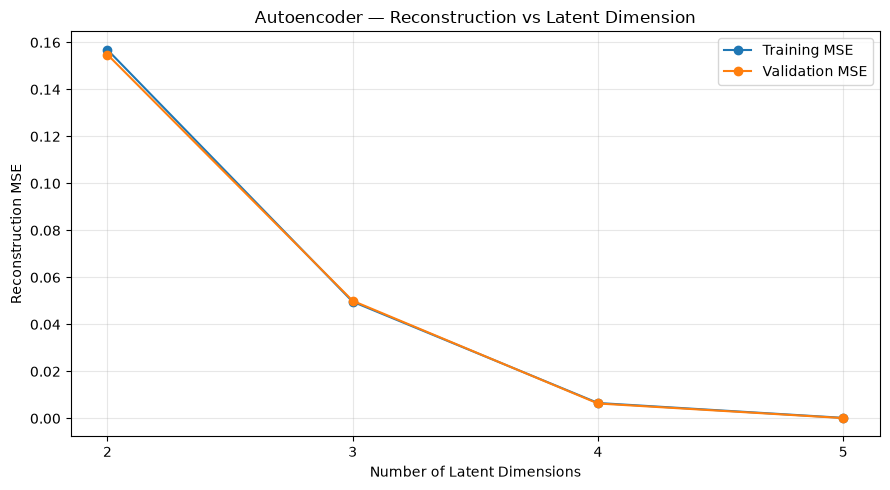

In [19]:
plot_ae_search(ae_search)


#### **6.2.6 Seed Stability**

In [21]:
ae_stability = AESeedStability(results_dir=data.results_dir, dataset_path=data.path).run(
    Autoencoder, train_fn=ae_trainer.train, force_retrain=False,
)
ae_stability.display()


Results directory: /home/joel-felipe-alba-acosta/Documents/UNIVERSITY/2026-2/APRENDIZAJE_NO_SUPERVISADO/Corte_3/PROYECTO_FINAL/results/07_autoencoder_vae/seed_stability/ae_seed_stability_5c3629fe9c374f20
Evaluation observations: 10000
Loading existing AE stability results.

RECONSTRUCTION METRICS BY SEED


,seed,latent_dim,hidden_dim,learning_rate,batch_size,train_mse,val_mse,best_epoch,epochs_trained,training_seconds,status,run_seconds
0,0,5,64,0.001,128,0.000508,0.000415,80,95,186.232933,Trained,186.454332
1,21,5,64,0.001,128,0.000253,0.000129,86,100,197.962883,Trained,198.188630
2,42,5,64,0.001,128,0.000220,0.000122,92,100,195.014401,Trained,195.254488
3,123,5,64,0.001,128,0.000301,0.000219,95,100,195.023991,Trained,195.247705
4,7,5,64,0.001,128,0.002369,0.002270,98,100,195.561027,Trained,195.781807
5,13,5,64,0.001,128,0.002788,0.002733,70,85,165.590923,Trained,165.812997
6,57,5,64,0.001,128,0.000526,0.000458,93,100,194.511847,Trained,194.730795
7,99,5,64,0.001,128,0.000308,0.000219,93,100,193.539963,Trained,193.753494
8,202,5,64,0.001,128,0.000230,0.000160,98,100,193.478305,Trained,193.701672
9,314,5,64,0.001,128,0.000165,0.000111,100,100,192.193794,Trained,192.406875



PAIRWISE REPRESENTATION STABILITY


,seed_a,seed_b,linear_cka,reconstruction_rmse
0,0,21,0.888824,0.021400
1,0,42,0.487343,0.021748
2,0,123,0.726911,0.022999
3,0,7,0.348228,0.051755
4,0,13,0.458554,0.056230
5,0,57,0.542802,0.017642
6,0,99,0.333610,0.022590
7,0,202,0.759184,0.022004
8,0,314,0.734368,0.021177
9,21,42,0.354375,0.013499



RECONSTRUCTION SUMMARY


,train_mse,val_mse,best_epoch
mean,0.000767,0.000683,90.500000
std,0.000967,0.000972,9.360081
min,0.000165,0.000111,70.000000
max,0.002788,0.002733,100.000000



PAIRWISE STABILITY SUMMARY


,linear_cka,reconstruction_rmse
mean,0.525486,0.031628
std,0.189328,0.016877
min,0.245914,0.013185
max,0.981576,0.056474


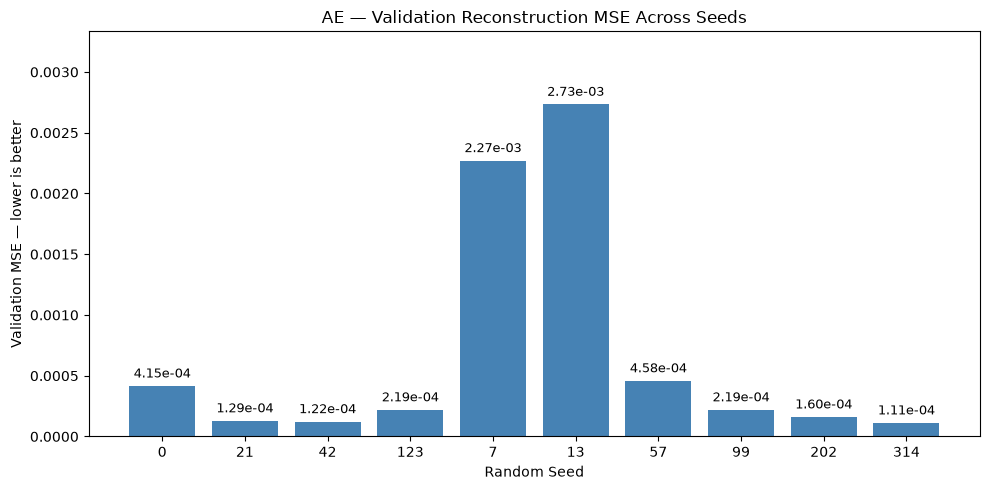

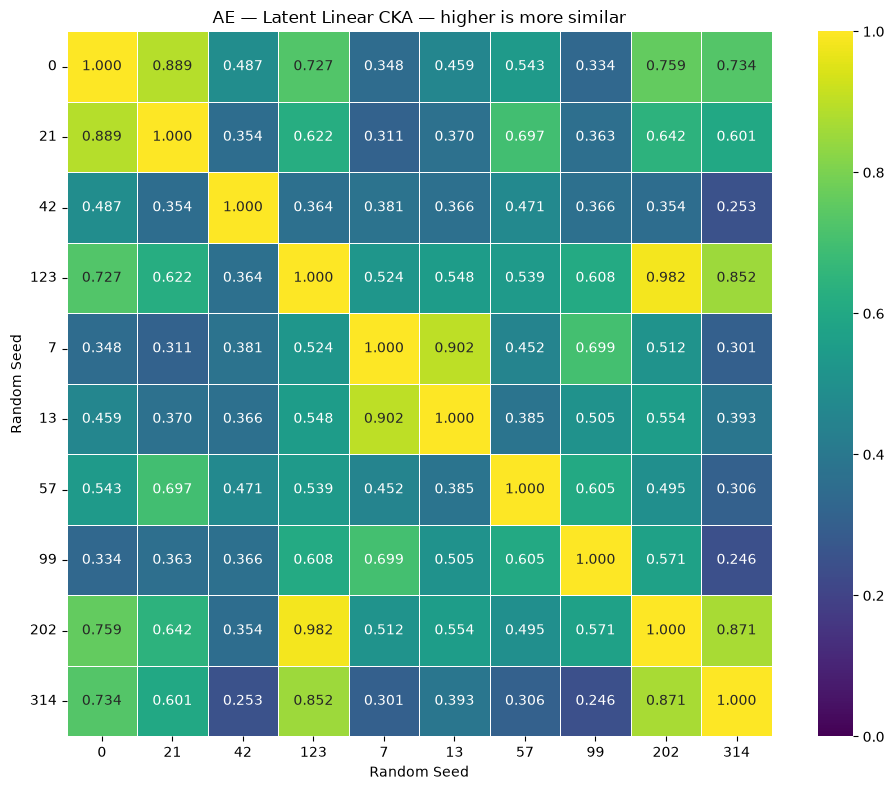

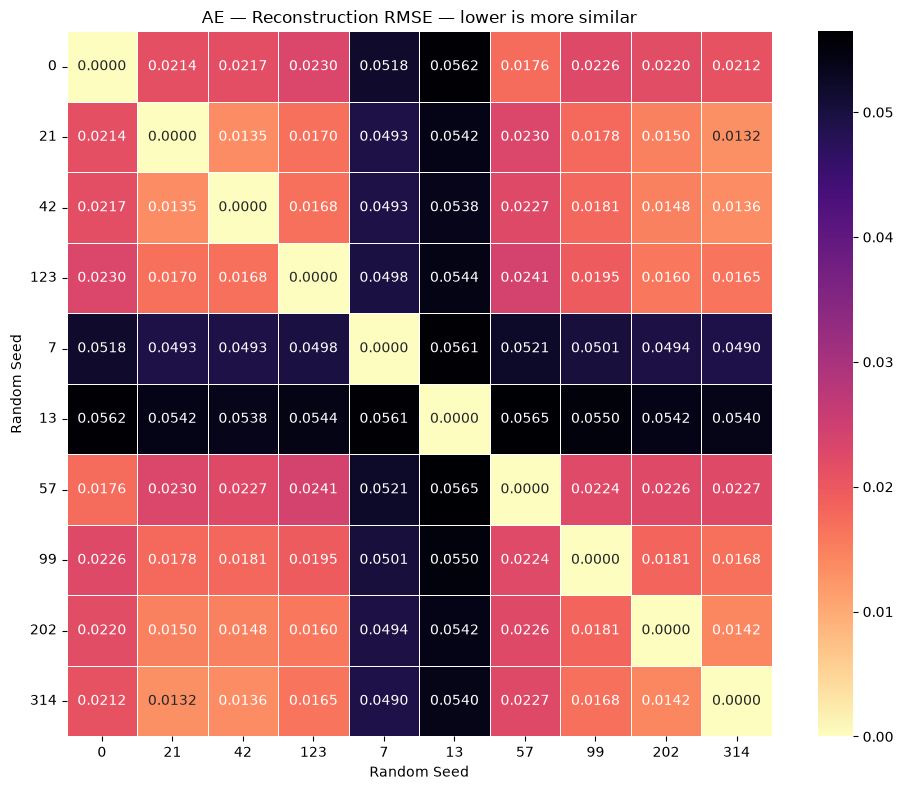

In [22]:
plot_ae_stability(ae_stability)


**Observations**

The selected AE configuration achieves low validation reconstruction errors across all ten seeds, with MSE values ranging approximately from **0.000111 to 0.00273**. However, seeds 7 and 13 produce noticeably higher errors; the largest MSE is approximately 25 times the smallest. Thus, reconstruction is accurate overall on the standardized features, but its quality remains sensitive to initialization.

The latent representations exhibit variable similarity across seeds. Excluding diagonal entries, linear CKA ranges approximately from **0.246 to 0.982**, with a mean of **0.525**. Some pairs learn highly similar representations, particularly seeds 123 and 202, whereas others show considerably lower agreement. Consequently, low reconstruction error does not guarantee that the model learns a consistent latent representation across training runs.

Pairwise reconstruction RMSE ranges approximately from **0.0132 to 0.0565**, indicating relatively small differences between reconstructed standardized values. Comparisons involving seeds 7 and 13 generally show larger differences, consistent with their higher validation errors. Overall, the AE reconstructs the observations well, but interpretations of its latent variables should acknowledge their sensitivity to the random seed.

### **6.3 Auto Encoder with 5 dimensions**

#### **6.3.1 Auto Encoder with "latent_dim": 5,"hidden_dim": 64,"learning_rate": 0.001 and "batch_size": 128**

In [23]:
ae_analysis = AEAnalysis(data).fit(stability=ae_stability, force_retrain=False)
ae_analysis.display()


Selected AE loaded from its best epoch.

HYPERPARAMETERS
{'latent_dim': 5, 'hidden_dim': 64, 'learning_rate': 0.001, 'batch_size': 128}

RECONSTRUCTION METRICS


,seed,latent_dim,hidden_dim,learning_rate,batch_size,train_mse,val_mse,best_epoch,epochs_trained,training_seconds
0,42,5,64,0.001,128,0.000221,0.000122,92,100,195.014401



Training latent shape: (108311, 5)
Validation latent shape: (36104, 5)


,AE 1,AE 2,AE 3,AE 4,AE 5
source_index,,,,,
105330,0.521402,1.622020,-0.810583,-2.040723,0.481732
111731,0.464539,2.941641,3.622469,-4.205315,-1.212479
26280,1.426061,1.563985,-0.648659,-2.519793,-0.367577
2124,0.838031,0.684177,0.488130,-1.445085,1.069226
34886,0.221113,0.461415,-0.908117,-0.767820,0.162686


#### **6.3.2 Latent Representations**

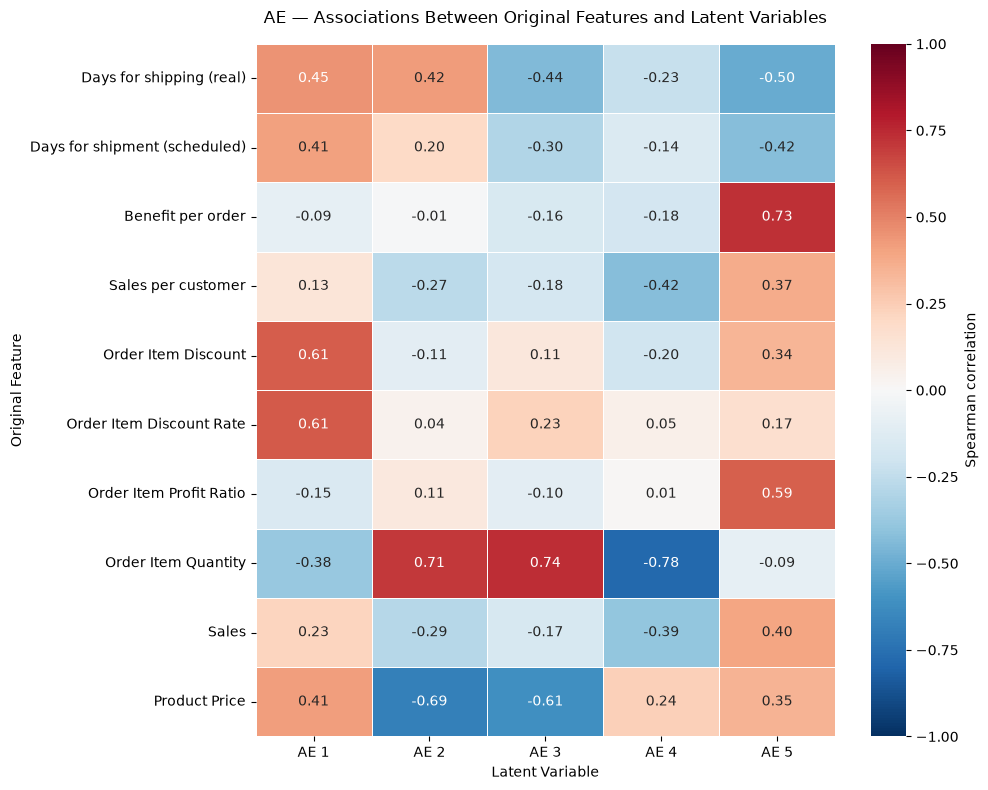

In [24]:
plot_ae_correlations(ae_analysis)


**Observations**

- **AE1 — Discounts and Longer Shipping Duration:** The strongest associations are positive correlations with Order Item Discount Rate and Order Item Discount (both approximately **0.61**). Actual shipping duration (**0.45**), product price (**0.41**), and scheduled shipping duration (**0.41**) show moderate positive associations, while quantity has a moderate negative association (**−0.38**). Higher scores therefore primarily reflect discount intensity, accompanied by longer shipping durations and higher product prices but less items.

- **AE2 — Higher Quantity and Lower Product Prices:** Order Item Quantity dominates with a strong positive correlation (**0.71**), alongside a substantial negative correlation with Product Price (**−0.69**). Actual shipping duration has a moderate positive association (**0.42**). This dimension mainly contrasts larger purchased quantities with lower product prices.

- **AE3 — Higher Quantity, Lower Prices, and Shorter Shipping Duration:** Quantity has the strongest positive association (**0.74**), while product price shows a substantial negative association (**−0.61**). Actual shipping duration is moderately negatively correlated (**−0.44**), with a weaker negative association for scheduled duration (**−0.30**). Higher scores describe larger quantities of lower-priced products associated with shorter shipping durations.

- **AE4 — Lower Quantity and Sales Values:** Quantity dominates through a strong negative correlation (**−0.78**). Sales per customer (**−0.42**) and Sales (**−0.39**) exhibit moderate negative associations, while the remaining relationships are weaker. Higher scores therefore primarily identify lower quantities, accompanied by lower transaction values.

- **AE5 — Profitability and Shorter Shipping Duration:** Benefit per order has the strongest positive correlation (**0.73**), followed by profit ratio (**0.59**). Actual and scheduled shipping durations show moderate negative associations (**−0.50** and **−0.42**). Sales (**0.40**), sales per customer (**0.37**), product price (**0.35**), and absolute discount (**0.34**) have smaller positive associations. This dimension primarily reflects higher profitability and shorter shipping durations, with secondary relationships to transaction value.

## **7. Variational Autoencoder (VAE)**

### **7.1 Notation**


**5. What is a Variational Autoencoder (VAE)?**

A **Variational Autoencoder (VAE)** is a probabilistic neural network that learns a latent representation of input data and reconstructs the original input from that representation.

Like a traditional Autoencoder (AE), a VAE consists of an **Encoder, a latent space, and a Decoder**.

However, the main difference is that **a VAE learns probability distributions in the latent space instead of directly learning a single latent vector for each observation**.

This allows a VAE to generate new observations by sampling from its learned latent distribution.

---

**1. VAE Architecture**

A VAE contains three main components.

**1.1 Encoder**

The Encoder transforms an input observation into the parameters of a probability distribution.

Instead of producing a single latent vector $z$, it produces:

- $\mu$: Mean vector.
- $\sigma^2$: Variance vector.

These parameters define a Gaussian distribution:

$$
\boxed{q_\phi(z\mid x)=\mathcal{N}(\mu_\phi(x),\operatorname{diag}(\sigma_\phi^2(x)))}
$$

Where:

- $x$: Original observation.
- $z$: Latent representation.
- $q_\phi(z\mid x)$: Approximate posterior distribution learned by the Encoder.
- $\phi$: Encoder parameters.

For example, if the input has 10 features and the latent space has 3 dimensions:

$$
\mathbb{R}^{10}\longrightarrow(\mu,\sigma^2)\in\mathbb{R}^{3}\times\mathbb{R}^{3}
$$

The Encoder produces two vectors, each containing three values.

**1.2 Latent Space and Sampling**

Unlike a traditional Autoencoder, a VAE does not use a fixed latent representation for each observation.

Instead, it samples a latent vector from the distribution estimated by the Encoder.

For example, suppose:

$$
\mu=[0.5,-0.2]
$$

$$
\sigma=[0.1,0.3]
$$

The latent vector is sampled from:

$$
z\sim\mathcal{N}(\mu,\operatorname{diag}(\sigma^2))
$$

However, directly sampling $z$ would make ordinary backpropagation through the sampling operation difficult.

To solve this, VAEs use the **Reparameterization Trick**.

$$
\boxed{z=\mu+\sigma\odot\epsilon}
$$

Where:

- $\mu$: Mean vector.
- $\sigma$: Standard deviation vector.
- $\epsilon\sim\mathcal{N}(0,I)$: Random noise.
- $\odot$: Element-wise multiplication.

**Numerical Example — Reparameterization**

Suppose the sampled noise is:

$$
\epsilon=[1,-0.5]
$$

Then:

$$
z=[0.5,-0.2]+[0.1,0.3]\odot[1,-0.5]
$$

$$
z=[0.5+0.1,-0.2-0.15]
$$

$$
\boxed{z=[0.6,-0.35]}
$$

The important idea is that the randomness is isolated in $\epsilon$, allowing gradients to propagate through $\mu$ and $\sigma$.

**1.3 Decoder**

The Decoder receives the sampled latent vector and reconstructs the original observation.

$$
\boxed{p_\theta(x\mid z)}
$$

This expression represents the probability distribution of the input conditioned on the latent variable.

For example, the Decoder might model a Gaussian distribution whose mean is the reconstruction:

$$
p_\theta(x\mid z)=\mathcal{N}(\mu_\theta(z),\sigma_x^2I)
$$

The reconstructed input can then be taken as:

$$
\hat{x}=\mu_\theta(z)
$$

Thus, the Decoder transforms the sampled latent representation into a reconstruction of the original features.

---

**2. How Does a VAE Learn?**

A VAE learns by optimizing two objectives simultaneously:

1. **Reconstruction:** Produce reconstructions similar to the original observations.
2. **Regularization:** Encourage the learned latent distributions to remain close to a predefined prior distribution.

The standard VAE loss is the negative Evidence Lower Bound (negative ELBO):

$$
\boxed{
L_{\text{VAE}}=
L_{\text{reconstruction}}+
D_{\mathrm{KL}}(q_\phi(z\mid x)\|p(z))
}
$$

Where:

- $L_{\text{reconstruction}}$: Negative expected log-likelihood of the original input under the Decoder.
- $D_{\mathrm{KL}}$: Kullback–Leibler divergence.
- $q_\phi(z\mid x)$: Distribution estimated by the Encoder.
- $p(z)$: Prior distribution, commonly $\mathcal{N}(0,I)$.

**2.1 Reconstruction Loss**

The reconstruction term measures how well the Decoder reconstructs the input.

For continuous numerical features, a common choice is MSE:

$$
\boxed{
L_{\text{reconstruction}}=
\frac{1}{p}\sum_{j=1}^{p}(x_j-\hat{x}_j)^2
}
$$

For example:

$$
x=[2,4,6],\qquad\hat{x}=[2.2,3.8,5.5]
$$

$$
L_{\text{reconstruction}}=
\frac{0.04+0.04+0.25}{3}
=\boxed{0.11}
$$

MSE is proportional to the negative log-likelihood under a Gaussian observation model with fixed variance. The exact scaling matters when combining it with the KL term.

**2.2 KL Divergence**

The **Kullback–Leibler divergence** measures how different the Encoder's latent distribution is from the prior distribution.

The standard prior is:

$$
\boxed{p(z)=\mathcal{N}(0,I)}
$$

For a diagonal Gaussian approximate posterior, KL divergence has a closed-form expression:

$$
\boxed{
D_{\mathrm{KL}}=
\frac{1}{2}\sum_{j=1}^{k}
\left(
\mu_j^2+\sigma_j^2-\log(\sigma_j^2)-1
\right)
}
$$

Where $k$ is the number of latent dimensions.

**Numerical Example — KL Divergence**

Suppose the Encoder produces a one-dimensional latent distribution with:

$$
\mu=0.5,\qquad\sigma=1
$$

Then:

$$
D_{\mathrm{KL}}=
\frac12(0.5^2+1^2-\log(1)-1)
$$

$$
=\frac12(0.25)=\boxed{0.125}
$$

A KL divergence of zero means the approximate posterior matches the prior.

The KL term encourages the latent distributions to remain organized around the prior, making sampling and generation possible.

**2.3 Combining Both Losses**

A commonly used variation is the **β-VAE**, which introduces a coefficient controlling the strength of regularization:

$$
\boxed{
L_{\beta\text{-VAE}}=
L_{\text{reconstruction}}+
\beta D_{\mathrm{KL}}
}
$$

- Smaller $\beta$: Places relatively more emphasis on reconstruction.
- Larger $\beta$: Places relatively more emphasis on matching the latent prior.

For example, suppose:

$$
L_{\text{reconstruction}}=0.11,\qquad D_{\mathrm{KL}}=0.125
$$

With $\beta=1$:

$$
L_{\text{VAE}}=0.11+0.125=\boxed{0.235}
$$

This is an illustrative combination of loss terms; in an actual implementation, their normalization and probabilistic interpretation must be consistent.

---

**3. VAE Training Pipeline**

A VAE is trained through the following steps:

1. **Input:** Provide a batch of observations $x$.
2. **Encoding:** Calculate the latent mean $\mu$ and variance $\sigma^2$.
3. **Sampling:** Generate $z=\mu+\sigma\odot\epsilon$.
4. **Decoding:** Reconstruct the input using the sampled latent vector.
5. **Loss:** Calculate reconstruction loss and KL divergence.
6. **Backpropagation:** Compute gradients through the reparameterized network.
7. **Optimization:** Update the parameters using an optimizer such as Adam.

These steps are repeated across batches and epochs.

---

**4. Variational Autoencoders for Anomaly Detection**

VAEs can also be used for **anomaly detection**.

A VAE trained predominantly on normal observations may learn a probability model that represents normal patterns better than unusual ones.

Several anomaly scores are possible.

**4.1 Reconstruction Error**

Similar to an Autoencoder:

$$
\boxed{
s_{\text{reconstruction}}(x_i)=
\frac1p\sum_{j=1}^{p}(x_{ij}-\hat{x}_{ij})^2
}
$$

A high reconstruction error may indicate an anomaly.

Because the VAE samples latent vectors, the reconstruction error can vary between samples. We can instead use the mean reconstruction or average the error over multiple latent samples.

**4.2 KL Divergence Score**

Another possibility is to measure how different an observation's approximate posterior is from the prior:

$$
\boxed{
s_{\text{KL}}(x_i)=
D_{\mathrm{KL}}(q_\phi(z\mid x_i)\|p(z))
}
$$

An unusually large KL divergence can indicate that an observation requires a latent distribution far from the prior.

However, KL divergence alone is not a universally reliable anomaly score.

**4.3 Combined Score**

We can also combine reconstruction error and KL divergence:

$$
\boxed{
s(x_i)=s_{\text{reconstruction}}(x_i)+
\lambda s_{\text{KL}}(x_i)
}
$$

Where $\lambda$ controls the relative contribution of the two components.

As with an Autoencoder, an empirical threshold can be established:

$$
\boxed{\tau=Q_{0.95}(s_{\text{train}})}
$$

An observation is flagged when:

$$
s(x_i)>\tau
$$

The score and threshold should be evaluated carefully because some anomalous observations may still receive low reconstruction errors or plausible latent distributions.

---

**5. Autoencoder vs. Variational Autoencoder**

| Characteristic | Autoencoder (AE) | Variational Autoencoder (VAE) |
|---|---|---|
| Learning approach | Deterministic representation learning | Probabilistic representation learning |
| Encoder output | Latent vector $z$ | Distribution parameters $\mu,\sigma^2$ |
| Latent representation | Deterministic | Sampled from a learned distribution |
| Decoder | Reconstructs the input | Models a conditional distribution of the input |
| Training loss | Reconstruction error | Reconstruction likelihood + KL regularization |
| Sampling | No explicit prior for generation | Supports sampling from a latent prior |
| Training complexity | Generally lower | Generally higher |
| Anomaly detection | Reconstruction error | Reconstruction, KL, or probabilistic scores |

**In summary:** A Variational Autoencoder extends the traditional Autoencoder by learning probability distributions in the latent space. Its Encoder estimates the mean and variance of a latent distribution, the reparameterization trick enables differentiable sampling, and the Decoder reconstructs the input. By combining reconstruction quality with KL regularization, a VAE learns a probabilistically structured latent space useful for representation learning, data generation, and anomaly detection.


![Backpropagation Pipeline](../results/07_autoencoder_vae/figures/vae.png)

### **7.2 Creation of the VAE**

#### **7.2.1 Preparing the Data**

In [ ]:
data.describe()


Device: cpu
Input features: 10
Training observations: 108311
Validation observations: 36104


#### **7.2.2 Defining VAE Architecture**

In [ ]:
vae_search = VAESearch(force_retrain=False)


#### **7.2.3 Defining Loss Function**

We'll use MSE reconstruction loss, averaged over features and observations, and a KL term averaged over observations. This is a practical β-VAE-style objective; its relative scaling is controlled by beta.

$$
L_{\text{VAE}}=L_{\text{reconstruction}}+\beta L_{\text{KL}}
$$

In [ ]:
vae_objective = vae_search.loss


#### **7.2.4 Training the VAE**

In [ ]:
vae_search.run(data)
vae_search.display()


Available CPU cores: 20
PyTorch threads: 14
Total configurations: 72
[1/72] latent=2 hidden=16 beta=0.001 lr=0.0005 | Val Loss=0.231855
[2/72] latent=2 hidden=16 beta=0.001 lr=0.001 | Val Loss=0.221889
[3/72] latent=2 hidden=16 beta=0.01 lr=0.0005 | Val Loss=0.291265
[4/72] latent=2 hidden=16 beta=0.01 lr=0.001 | Val Loss=0.262070
[5/72] latent=2 hidden=16 beta=0.1 lr=0.0005 | Val Loss=0.507716
[6/72] latent=2 hidden=16 beta=0.1 lr=0.001 | Val Loss=0.501090
[7/72] latent=2 hidden=16 beta=1.0 lr=0.0005 | Val Loss=0.992625
[8/72] latent=2 hidden=16 beta=1.0 lr=0.001 | Val Loss=0.992653
[9/72] latent=2 hidden=32 beta=0.001 lr=0.0005 | Val Loss=0.181511
[10/72] latent=2 hidden=32 beta=0.001 lr=0.001 | Val Loss=0.161946
[11/72] latent=2 hidden=32 beta=0.01 lr=0.0005 | Val Loss=0.234892
[12/72] latent=2 hidden=32 beta=0.01 lr=0.001 | Val Loss=0.222663
[13/72] latent=2 hidden=32 beta=0.1 lr=0.0005 | Val Loss=0.487366
[14/72] latent=2 hidden=32 beta=0.1 lr=0.001 | Val Loss=0.485310
[15/72] lat

,latent_dim,hidden_dim,beta,learning_rate,best_epoch,train_loss,val_loss,val_reconstruction,val_kl
0,5,64,0.001,0.0010,100,0.016857,0.014456,0.000413,14.043323
1,5,64,0.001,0.0005,88,0.017689,0.015193,0.000460,14.732680
2,5,32,0.001,0.0010,98,0.019306,0.016743,0.001413,15.329605
3,5,32,0.001,0.0005,100,0.020117,0.017558,0.002046,15.512107
4,5,16,0.001,0.0010,98,0.028683,0.026370,0.010848,15.522491
5,5,16,0.001,0.0005,100,0.033244,0.030991,0.015341,15.649273
6,3,32,0.001,0.0005,100,0.082238,0.080327,0.068571,11.756556
7,3,64,0.001,0.0010,100,0.082622,0.081869,0.069887,11.982150
8,3,32,0.001,0.0010,99,0.083691,0.083098,0.071017,12.080142
9,3,64,0.001,0.0005,100,0.088502,0.087625,0.075945,11.679094



Best configuration:
{'latent_dim': 5, 'hidden_dim': 64, 'beta': 0.001, 'learning_rate': 0.001}

Best validation loss:
0.014456330906907656


**Observations**

Among the configurations evaluated, the best model used a five-dimensional latent representation, a hidden-layer width of 64 neurons, β = 0.001, and a learning rate of 0.001. It achieved the lowest validation loss of approximately 0.01446 under the selected evaluation criterion.

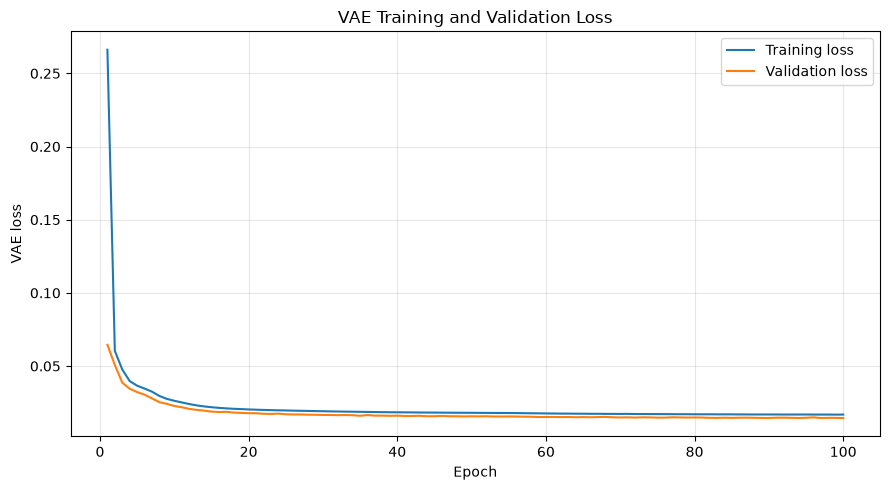

In [ ]:
plot_vae_history(vae_search)


**Observations**

The VAE learns rapidly during the first 10 epochs, when both training and validation losses decrease sharply. The curves approach a plateau around epochs 20–30, followed by smaller improvements. Their similar trajectories show no clear evidence of overfitting during training.

#### **7.2.5 Calculating Anomaly Scores**

In [ ]:
vae_analysis = VAEAnalysis(vae_search).score()


Train scores: (108311,)
Validation scores: (36104,)


#### **7.2.6 Stablishing Anomaly tresholds**

In [ ]:
vae_analysis = vae_analysis.flag()


,vae_score,vae_anomaly_05,vae_anomaly_01
0,0.000063,0,0
1,0.000228,0,0
2,0.000164,0,0
3,0.000301,0,0
4,0.000078,0,0


Alpha=0.05 | Threshold=0.001204 | Anomalies=1761 | Rate=4.88%
Alpha=0.01 | Threshold=0.002461 | Anomalies=329 | Rate=0.91%


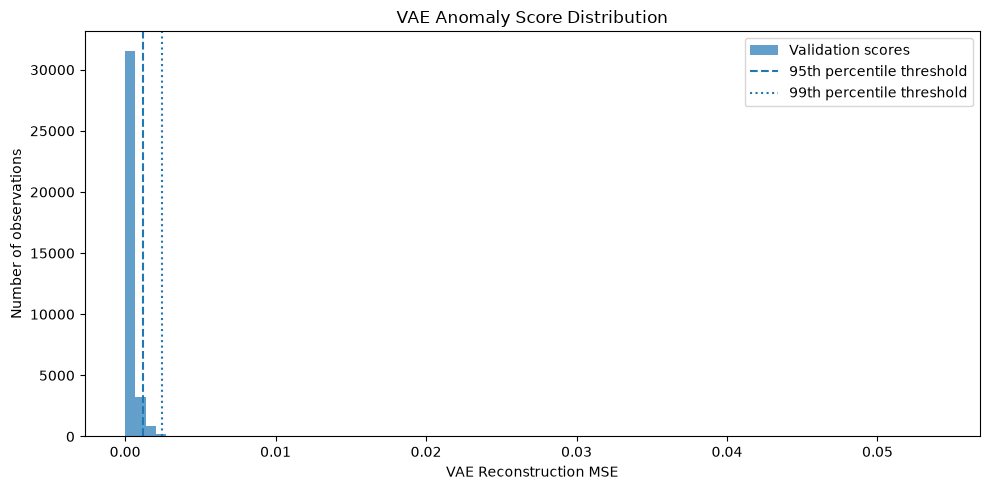

In [ ]:
plot_vae_score_distribution(vae_analysis)


#### **7.2.7 Saving the Results**

In [ ]:
vae_analysis.save()


All VAE results saved successfully.


#### **7.2.8 Seed Stability**

In [ ]:
vae_seed_trainer = VAESeedTrainer(data)


In [ ]:
vae_stability = VAESeedStability(force_retrain=False).run(
    vae_search, trainer=vae_seed_trainer,
)
vae_stability.display()


Existing VAE pairwise stability results found. Loading...

Pairwise comparisons: 45


,seed_a,seed_b,spearman,jaccard_05,jaccard_01
0,0,21,0.485854,0.122108,0.047138
1,0,42,0.569930,0.195441,0.041602
2,0,123,0.361545,0.123356,0.086039
3,0,7,0.474610,0.131065,0.074554
4,0,13,0.501691,0.356148,0.143608
5,0,57,0.526533,0.189644,0.074766
6,0,99,0.551978,0.321797,0.035439
7,0,202,0.556997,0.258313,0.021708
8,0,314,0.518638,0.149230,0.057057
9,21,42,0.522504,0.168369,0.054264



Stability summary:


,spearman,jaccard_05,jaccard_01
mean,0.5191,0.2272,0.1657
std,0.0722,0.0876,0.1713
min,0.3615,0.1204,0.0217
max,0.6818,0.4432,0.6859


Available columns:
['seed_a', 'seed_b', 'spearman', 'jaccard_05', 'jaccard_01']

Pairwise comparisons: 45


,seed_a,seed_b,spearman,jaccard_05,jaccard_01
0,0,21,0.485854,0.122108,0.047138
1,0,42,0.569930,0.195441,0.041602
2,0,123,0.361545,0.123356,0.086039
3,0,7,0.474610,0.131065,0.074554
4,0,13,0.501691,0.356148,0.143608


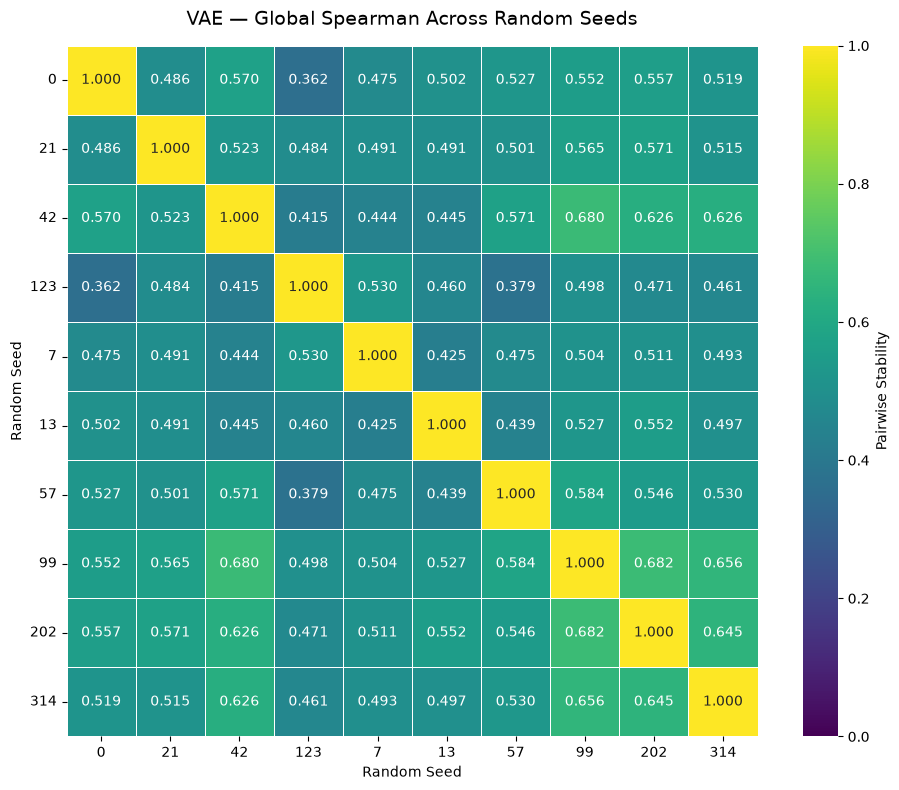

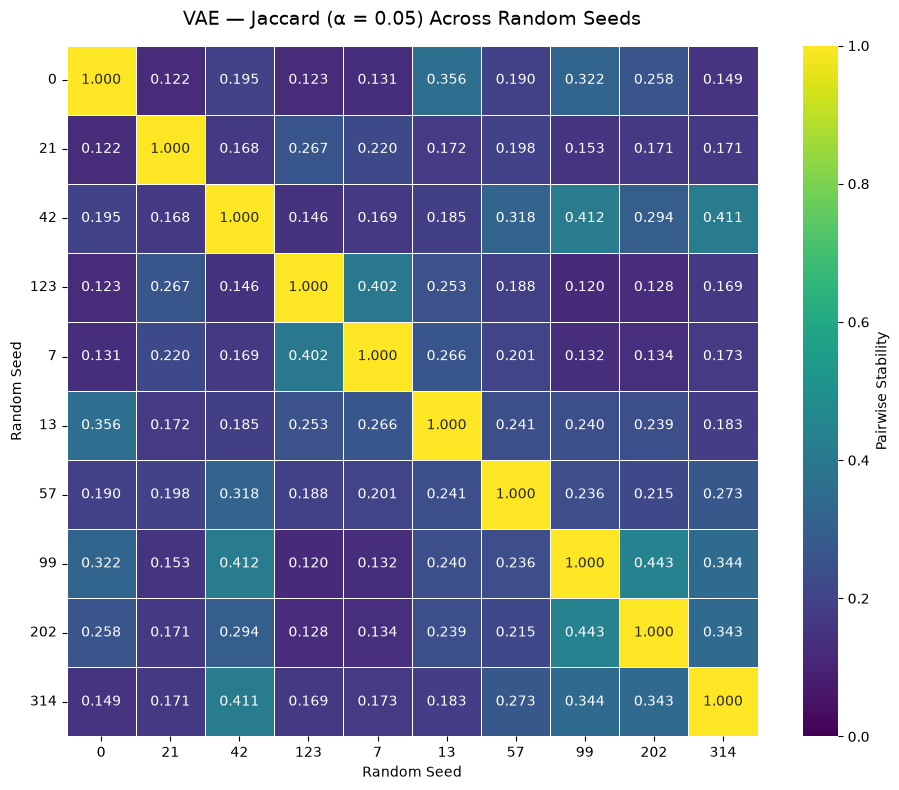

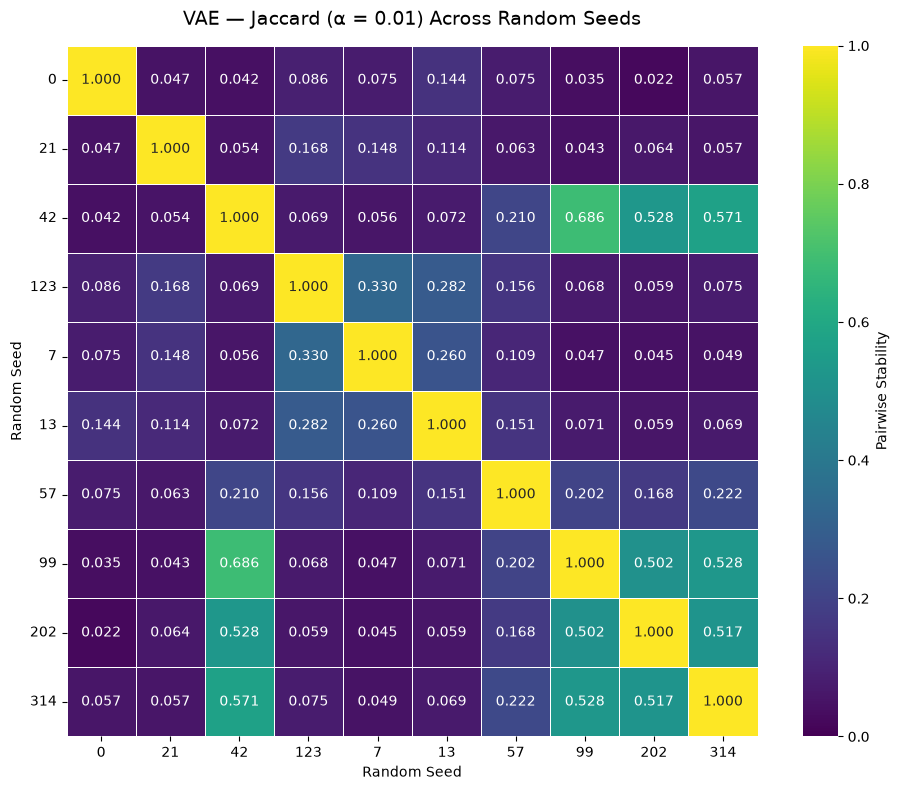


VAE SEED STABILITY SUMMARY


,Metric,Mean,SD,Minimum,Maximum
0,Global Spearman,0.5191,0.0722,0.3615,0.6818
1,Jaccard (α = 0.05),0.2272,0.0876,0.1204,0.4432
2,Jaccard (α = 0.01),0.1657,0.1713,0.0217,0.6859



All VAE stability visualizations saved successfully.


In [ ]:
plot_vae_stability(vae_stability)


**Observations**

The VAE exhibits moderate ranking stability across random seeds, with pairwise Spearman correlations ranging approximately from 0.36 to 0.68. This indicates that the overall ordering of anomaly scores changes substantially between training runs, although some positive agreement remains.

Jaccard similarities show limited agreement between the observations flagged by different seeds. At $\alpha=0.05$, similarities range approximately from 0.12 to 0.44. At $\alpha=0.01$, many comparisons show even lower overlap, although some seed pairs achieve substantially higher agreement, reaching approximately 0.69. Therefore, the stricter threshold does not consistently produce more stable detections.

These results indicate that the VAE’s anomaly rankings and threshold-based flags are sensitive to the training seed. Interpretations based on a single run should consequently acknowledge this variability. Examining observations repeatedly flagged across seeds could help distinguish consistent detections from those that depend strongly on a particular training run.

### **7.3 Anomaly Detection**

#### **7.3.1 Anomaly Detection with $\alpha=0.05$**

VAE | 95TH PERCENTILE | VALIDATION
Threshold: 0.001204
Total observations: 36,104
Anomalous: 1,761
Non-anomalous: 34,343
Anomaly rate: 4.88%

VAE - ORIGINAL FEATURE DESCRIPTIVE STATISTICS


count      mean       std  \
Group         Feature                                                      
Anomalous     Days for shipping (real)        1761.0    3.1482    1.9526   
              Days for shipment (scheduled)   1761.0    2.2340    1.4732   
              Benefit per order               1761.0  -75.2916  270.6841   
              Sales per customer              1761.0  254.2938  290.4966   
              Order Item Discount             1761.0   27.9063   47.4364   
              Order Item Discount Rate        1761.0    0.0988    0.0770   
              Order Item Profit Ratio         1761.0   -0.4412    0.9715   
              Order Item Quantity             1761.0    2.2754    1.3983   
              Sales                           1761.0  282.1995  323.3891   
              Product Price                   1761.0  200.8175  334.6168   
Non-Anomalous Days for shipping (real)       34343.0    3.5206    1.6092   
              Days for shipment (scheduled)  34343.0    2.9642    1.3620   
              Benefit per order              34343.0   27.4076   81.1244   
              Sales per customer             34343.0  179.3779  102.0881   
              Order Item Discount            34343.0   20.2233   19.7375   
              Order Item Discount Rate       34343.0    0.1015    0.0702   
              Order Item Profit Ratio        34343.0    0.1503    0.4038   
              Order Item Quantity            34343.0    2.1037    1.4473   
              Sales                          34343.0  199.6010  112.2450   
              Product Price                  34343.0  139.1013  121.0118   

                                                 min     25%     50%     75%  \
Group         Feature                                                          
Anomalous     Days for shipping (real)          0.00    2.00    3.00    5.00   
              Days for shipment (scheduled)     0.00    1.00    2.00    4.00   
              Benefit per order             -2205.00 -137.17    2.92   49.60   
              Sales per customer                8.47   79.98  175.98  319.97   
              Order Item Discount               0.00    4.00   12.00   30.00   
              Order Item Discount Rate          0.00    0.03    0.09    0.16   
              Order Item Profit Ratio          -2.75   -1.50    0.05    0.33   
              Order Item Quantity               1.00    1.00    2.00    3.00   
              Sales                             9.99   99.95  199.98  399.96   
              Product Price                     9.99   49.98   79.99  215.82   
Non-Anomalous Days for shipping (real)          0.00    2.00    3.00    5.00   
              Days for shipment (scheduled)     0.00    2.00    4.00    4.00   
              Benefit per order              -793.72    8.45   32.39   65.34   
              Sales per customer                8.29  105.58  163.99  245.98   
              Order Item Discount               0.00    5.50   14.00   29.99   
              Order Item Discount Rate          0.00    0.04    0.09    0.16   
              Order Item Profit Ratio          -2.75    0.08    0.28    0.36   
              Order Item Quantity               1.00    1.00    1.00    3.00   
              Sales                             9.99  119.98  199.92  299.95   
              Product Price                     9.99   50.00   65.00  199.99   

                                                 max  
Group         Feature                                 
Anomalous     Days for shipping (real)          6.00  
              Days for shipment (scheduled)     4.00  
              Benefit per order               720.00  
              Sales per customer             1679.99  
              Order Item Discount             500.00  
              Order Item Discount Rate          0.25  
              Order Item Profit Ratio           0.50  
              Order Item Quantity               5.00  
              Sales                          1999.99  
        


VAE - ANOMALY SCORE DESCRIPTIVE STATISTICS


,Anomalous,Non-Anomalous
count,1761.000000,34343.000000
mean,0.002438,0.000309
std,0.003182,0.000230
min,0.001204,0.000014
25%,0.001373,0.000144
50%,0.001625,0.000239
75%,0.002162,0.000402
max,0.054109,0.001203


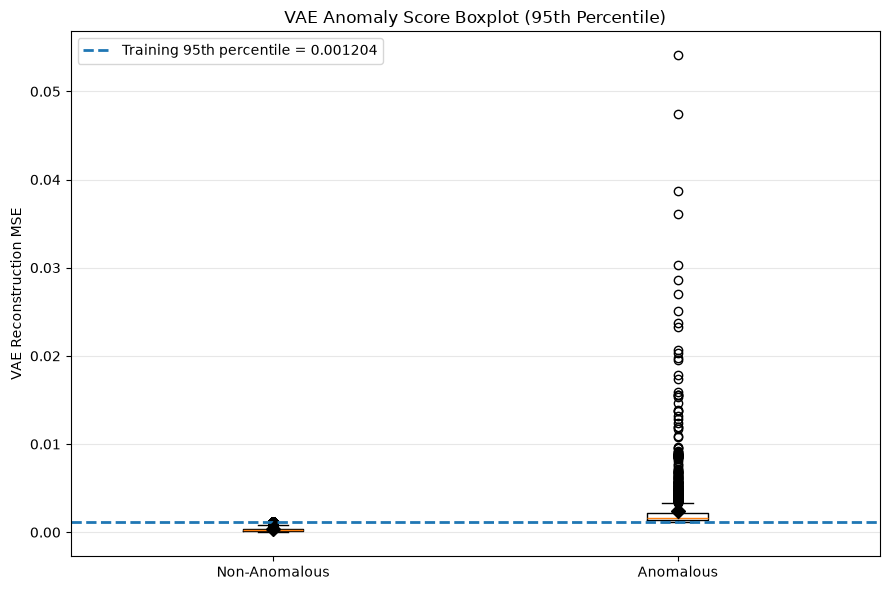

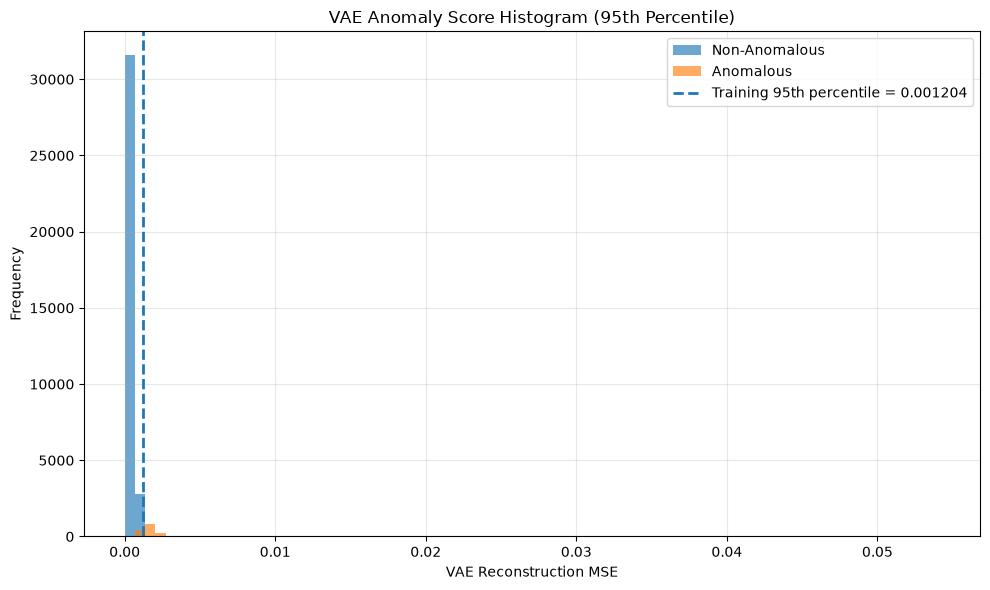

In [ ]:
VAEAnomalyAnalysis(vae_analysis, alpha=0.05).present()


**Observations**

Using the 5% criterion, the VAE flags 1,761 validation observations (4.88%) above the training-derived reconstruction-error threshold of 0.001204. Their mean score is 0.002438, compared with 0.000309 for non-flagged observations, while their median is 0.001625 versus 0.000239. Higher scores indicate larger mean squared errors when reconstructing the standardized numerical features. The maximum of 0.054109 reveals that some observations are reconstructed substantially less accurately than most flagged transactions.

The clearest descriptive distinction is weaker profitability. Flagged observations have a median benefit per order of 2.92, compared with 32.39 for non-flagged observations, and a median profit ratio of 0.05 versus 0.28. Their mean benefit is negative at −75.29 despite the positive median, indicating that substantial losses among some transactions pull the average downward. Median sales is almost identical between groups, although higher mean sales among flagged observations indicates the influence of unusually large transactions.

The flagged group therefore contains varied financial and operational profiles rather than a single type of problematic order. Median scheduled shipping is shorter, while median actual shipping is unchanged; however, these separate summaries do not establish the reason for each detection. Individual feature-level reconstruction errors are needed to identify the main contributions to each score. High reconstruction error indicates poor fit to the learned representation, rather than confirmed fraud or incorrect data.

#### **7.3.2 Anomaly Detection with $\alpha=0.01$**

VAE | 99TH PERCENTILE | VALIDATION
Threshold: 0.002461
Total observations: 36,104
Anomalous: 329
Non-anomalous: 35,775
Anomaly rate: 0.91%

VAE - ORIGINAL FEATURE DESCRIPTIVE STATISTICS


count      mean       std  \
Group         Feature                                                      
Anomalous     Days for shipping (real)         329.0    3.8267    1.6831   
              Days for shipment (scheduled)    329.0    2.7720    1.2638   
              Benefit per order                329.0  -76.3192  441.1339   
              Sales per customer               329.0  502.1747  531.9389   
              Order Item Discount              329.0   59.3332   88.5081   
              Order Item Discount Rate         329.0    0.1081    0.0805   
              Order Item Profit Ratio          329.0   -0.6465    1.1701   
              Order Item Quantity              329.0    1.6565    1.0421   
              Sales                            329.0  561.5071  593.1189   
              Product Price                    329.0  515.7840  620.2736   
Non-Anomalous Days for shipping (real)       35775.0    3.4995    1.6288   
              Days for shipment (scheduled)  35775.0    2.9301    1.3776   
              Benefit per order              35775.0   23.3062   92.4210   
              Sales per customer             35775.0  180.0971  104.3055   
              Order Item Discount            35775.0   20.2418   20.0423   
              Order Item Discount Rate       35775.0    0.1013    0.0704   
              Order Item Profit Ratio        35775.0    0.1285    0.4487   
              Order Item Quantity            35775.0    2.1163    1.4480   
              Sales                          35775.0  200.3386  114.6518   
              Product Price                  35775.0  138.6751  122.1521   

                                                 min     25%     50%      75%  \
Group         Feature                                                           
Anomalous     Days for shipping (real)          0.00    2.00    4.00     5.00   
              Days for shipment (scheduled)     0.00    2.00    2.00     4.00   
              Benefit per order             -2205.00 -151.15    8.80    83.29   
              Sales per customer                8.47  129.99  199.98  1125.00   
              Order Item Discount               0.00    5.00   24.00    72.00   
              Order Item Discount Rate          0.00    0.03    0.10     0.17   
              Order Item Profit Ratio          -2.75   -1.65    0.05     0.30   
              Order Item Quantity               1.00    1.00    1.00     2.00   
              Sales                            11.29  129.99  199.99  1500.00   
              Product Price                     9.99   59.99   99.99  1500.00   
Non-Anomalous Days for shipping (real)          0.00    2.00    3.00     5.00   
              Days for shipment (scheduled)     0.00    2.00    4.00     4.00   
              Benefit per order              -904.75    7.27   31.50    64.86   
              Sales per customer                8.29  103.99  163.99   247.40   
              Order Item Discount               0.00    5.40   14.00    29.99   
              Order Item Discount Rate          0.00    0.04    0.09     0.16   
              Order Item Profit Ratio          -2.75    0.08    0.27     0.36   
              Order Item Quantity               1.00    1.00    1.00     3.00   
              Sales                             9.99  119.98  199.92   299.95   
              Product Price                     9.99   50.00   59.99   199.99   

                                                 max  
Group         Feature                                 
Anomalous     Days for shipping (real)          6.00  
              Days for shipment (scheduled)     4.00  
              Benefit per order               720.00  
              Sales per customer             1679.99  
              Order Item Discount             500.00  
              Order Item Discount Rate          0.25  
              Order Item Profit Ratio           0.50  
              Order Item Quantity               5.00  
              Sales                      


VAE - ANOMALY SCORE DESCRIPTIVE STATISTICS


,Anomalous,Non-Anomalous
count,329.000000,35775.000000
mean,0.006059,0.000361
std,0.006140,0.000346
min,0.002461,0.000014
25%,0.003006,0.000147
50%,0.004163,0.000249
75%,0.006156,0.000436
max,0.054109,0.002459


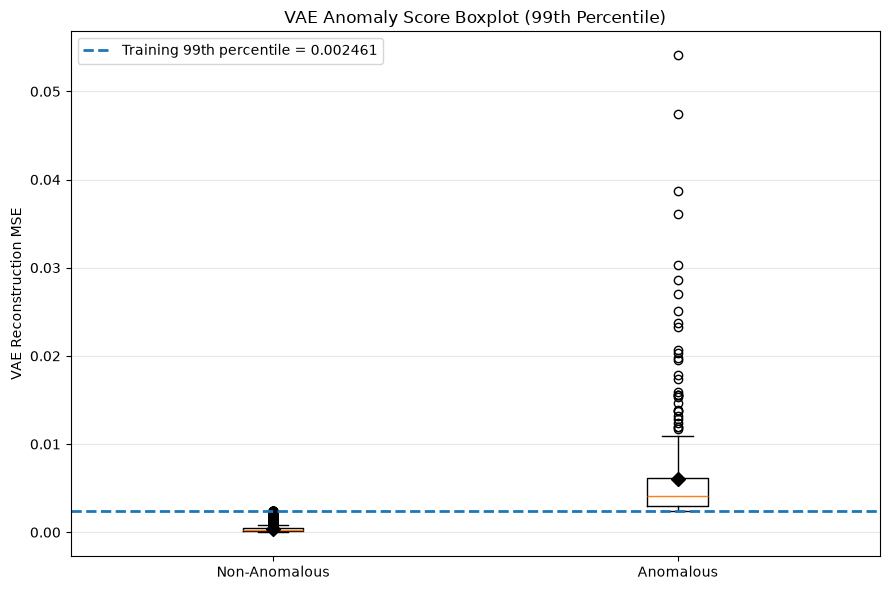

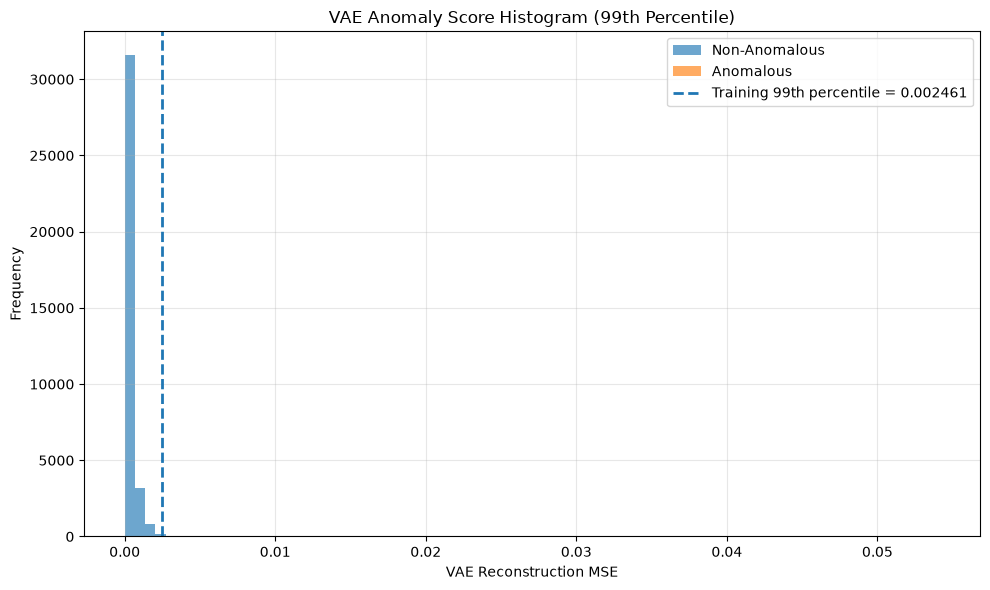

In [ ]:
VAEAnomalyAnalysis(vae_analysis, alpha=0.01).present()


**Observations**

Using the 1% criterion increases the VAE reconstruction-error threshold from 0.001204 to 0.002461, reducing flagged validation observations from 1,761 (4.88%) to 329 (0.91%). These observations form a subset of those identified at 5%. Their mean score increases from 0.002438 to 0.006059, while their median rises from 0.001625 to 0.004163. This reflects the selection of transactions with larger reconstruction errors; the model and individual scores remain unchanged.

Compared with the 5% anomalous group, mean sales increases from 282.20 to 561.51, mean product price from 200.82 to 515.78, and mean absolute discount from 27.91 to 59.33. However, median sales remains approximately 199.99, indicating that large transactions strongly influence the averages. Median product price increases from 79.99 to 99.99, and median absolute discount rises from 12.00 to 24.00. Mean benefit changes only slightly, from −75.29 to −76.32, while median benefit increases from 2.92 to 8.80 and median profit ratio remains 0.05. The stricter group therefore does not uniformly exhibit weaker profitability.

Operational characteristics also change: median quantity decreases from two items to one, while median actual shipping duration increases from three to four days and median scheduled duration remains two days. Overall, the 1% criterion selects transactions with greater reconstruction errors and higher average sales, absolute discounts, product prices, and actual shipping durations than the 5% anomalous group. These group differences do not establish which features caused each flag; individual reconstruction-error contributions are needed for that interpretation.